# Customer Feedback Classification
_Using a dataset to build an NLP classification model_

---

## Table of Contents
1. [Introduction](#introduction)  
2. [Initial Setup](#initial-setup)  
3. [Data Ingestion](#data-ingestion)  
4. [Exploratorty Data Analysis](#exploritory-data-analaysis)  
5. [Data Cleaning & Preprocessing](#data-cleaning-preprocessing)  
6. [Modelling / Training](#modelling-training)  
7. [Evaluation](#evaluation)  
8. [Conclusion](#conclusion)

## Introduction <a id='introduction'></a>
This notebook’s primary objective is to build an NLP classification model that can automatically assign customer emails to one of five predefined categories.

### Target Categories
- Damaged Property  
- General Inquiry  
- Missed Collection  
- Positive Feedback  
- Service Complaint

## Inital Setup <a id='initial-setup'></a>

In [6]:
# Import Libraries and Modules
import tqdm
import string
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from transformers import RobertaTokenizer, RobertaModel
from torch.optim import AdamW
from dataset_loader import DatasetLoader
from IPython.display import HTML, display

# Define Constants
DATASET_ARCHIVE_PATH = './AI_Portfolio_Task1_Dataset.zip'
DATASET_EXTRACT_DIR = './dataset'

MODEL_NAME = 'roberta-base'
MAX_LEN = 128
BATCH_SIZE = 32
EPOCHS = 10
LR = 2e-5
DROPOUT = 0.3
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

display(HTML(
    pd.DataFrame({
        'PyTorch Version': [torch.__version__],
        'Device': [str(DEVICE)]
    }).to_html(index=False)
))

PyTorch Version,Device
2.10.0+cu130,cuda


## Data Ingestion <a id='data-ingestion'></a>

The dataset is ingested from the project archive using the custom `DatasetLoader`, then stored in-memory as Pandas DataFrames (`train_df` and `test_df`). The use of a DataFrame allows for:  

- **EDA Integration** - Direct use of Pandas/Seaborn for concise and detailed exploratory analysis.
- **PyTorch Compatibility** - DataFrames can be cleanly wrapped in custom `Dataset` classes for tokenisation and batching.
- **Quality Tracking** - Validation and diagnostic fields can be added without changing the core dataset layout.

The chosen schema includes the standard ingestion fields and extra ones added through analysis/preprocessing:

| Column Name              | Data Type        | Example Value                                  | Description                 |
|--------------------------|------------------|------------------------------------------------|-----------------------------|
| `label`                  | string           | `MissedCollection`                             | Classification target.      |
| `message`                | string           | `Our waste wasn't picked up yesterday.`        | Raw customer feedback text. |

In [7]:
# Load dataset using DatasetLoader
loader = DatasetLoader(DATASET_ARCHIVE_PATH, DATASET_EXTRACT_DIR)

# Extract and display dataframe dataset splits
if loader.train_df is not None:
    train_df = loader.train_df.copy()
    print(f"Training set loaded: {train_df.shape[0]} rows, {train_df.shape[1]} columns")
else:
    raise ValueError("Failed to load training dataset")

if loader.test_df is not None:
    test_df = loader.test_df.copy()
    print(f"Test set loaded: {test_df.shape[0]} rows, {test_df.shape[1]} columns")
else:
    raise ValueError("Failed to load test dataset")

train_df.head()

Dataset already extracted: E:\feedback-classification\dataset
Training set loaded: 2119 rows, 2 columns
Test set loaded: 904 rows, 2 columns


,label,message
0,GeneralInquiry,Do you recycle tetrapaks?
1,ServiceComplaint,"absolutely disgusting service, bins left open ..."
2,MissedCollection,Again missed my place – 21 Cloverfield. Gettin...
3,MissedCollection,Why do you keep missing our address?
4,PositiveFeedback,Love your service! Always prompt and the staff...


## Exploritory Data Analaysis <a id='exploritory-data-analaysis'></a>

The aim within this section is to explore the available data looking into items such as `Class Distribution`, `Data Quality Checks`, `Text Length Analysis`, `Vocabulary Analysis`, `Text Characteristics`. Giving more insight into how the data is structured and what I can do in preprocessing to accomodate while also influencing my decision of model type to use for the given task.

### Class Distribution

The objective of this check is to understand how evenly the five target classes are represented before fine-tuning a pre-trained transformer model.

- Identify potential **class imbalance** that could bias predictions towards majority classes.  
- Inform whether to use **class weights**, **re-sampling**, or **stratified batching/splitting** during training.  
- Ensure evaluation focuses on robust metrics (e.g., **macro F1**, per-class recall), not only overall accuracy.  
- Establish a reliable baseline for interpreting model behaviour and errors across all categories.

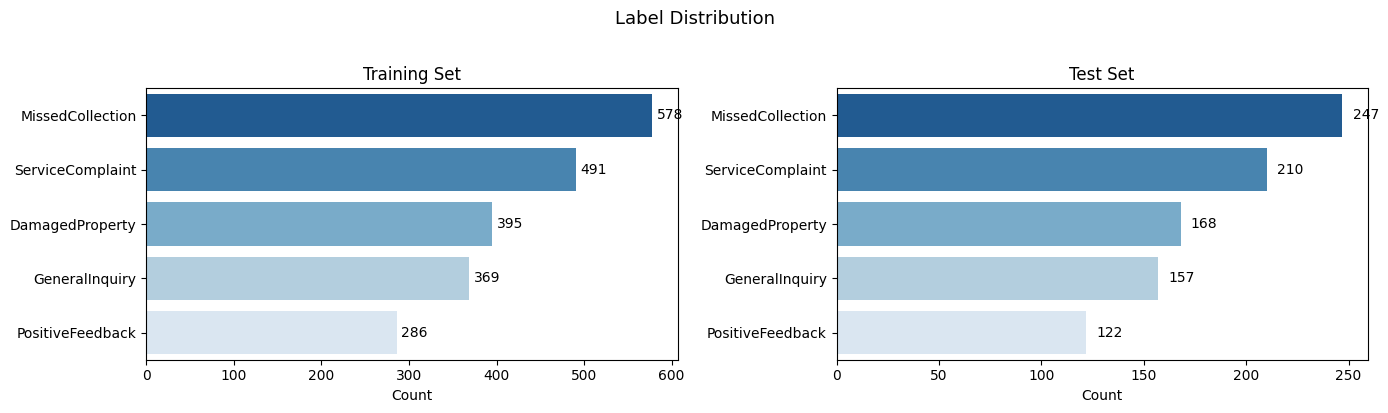

Label,Proportion
MissedCollection,27.28%
ServiceComplaint,23.17%
DamagedProperty,18.64%
GeneralInquiry,17.41%
PositiveFeedback,13.50%


In [8]:
# Evaluate Label Distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, df, title in zip(axes, [train_df, test_df], ['Training Set', 'Test Set']):
    counts = df['label'].value_counts()
    sns.barplot(x=counts.values, y=counts.index, ax=ax, hue=counts.index, palette='Blues_r', legend=False)
    ax.set_title(title)
    ax.set_xlabel('Count')
    ax.set_ylabel('')
    for i, v in enumerate(counts.values):
        ax.text(v + 5, i, str(v), va='center')

plt.suptitle('Label Distribution', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

training_breakdown = (
    train_df['label']
    .value_counts(normalize=True)
    .rename_axis('Label')
    .reset_index(name='Proportion')
)

display(HTML(training_breakdown.to_html(index=False, float_format=lambda x: f"{x * 100:.2f}%")))

#### Class Distribution Findings

After analysis I have identified class imbalance. In the training set, **Missed Collection** is the largest class at **27.28%**, while **Positive Feedback** is the smallest being **13.50%**. The test set has the same pattern (e.g., **247/904** for Missed Collection), which shows that the split is consistent.

Data quality is strong: both train and test sets show **0 duplicates** and **0 missing values** for `label` and `message`. This means there are no structural data issues likely to mess with modelling results and no extra preprocessing required for this topic.

Evaluation should focus on **macro F1**, **per-class precision/recall**, and a **confusion matrix**, rather than just accuracy, to make sure the classes with weaker representation are not being improperly classified.


### Data Quality Checks

The objective of this section is to assess baseline dataset quality before preprocessing and record any issues that could affect downstream modelling.

- Identify duplicate records in the training and test datasets.  
- Check for missing values in critical fields (`label` and `message`).  
- Confirm the core dataset structure is complete and fit for analysis.  
- Flag any quality issues to be handled in the preprocessing stage.

In [9]:
# Duplicates and Missing Values
duplicate_train = train_df.duplicated().sum()
duplicate_test = test_df.duplicated().sum()

missing_train = train_df.isnull().sum()
missing_test = test_df.isnull().sum()

data_quality_table = pd.DataFrame({
    'Dataset': ['Train', 'Test'],
    'Duplicates': [duplicate_train, duplicate_test],
    'Missing Label': [missing_train.get('label', 0), missing_test.get('label', 0)],
    'Missing Message': [missing_train.get('message', 0), missing_test.get('message', 0)]
})

data_quality_table['Total Missing'] = (
    data_quality_table['Missing Label'] + data_quality_table['Missing Message']
)

display(HTML(data_quality_table.to_html(index=False)))

Dataset,Duplicates,Missing Label,Missing Message,Total Missing
Train,0,0,0,0
Test,0,0,0,0


#### Data Quality Findings

This was an ideal outcome where no missing/duplicate values were found in the both train and test splits meaning no pre-processing is required.

### Text Length Analysis

The objective of this section is to examine the tokenised length distributions of customer feedback messages across both dataset splits and target classes.

- Identify if message length varies **between classes**, which may introduce length-based bias during training.
- Detect any **outliers or unusually short/long messages** that may require truncation or filtering during preprocessing.
- Assess whether the chosen `MAX_LEN` of **128 tokens** is appropriate given the observed text lengths.
- Ensure both **train and test splits** share a consistent length distribution, confirming the split is representative.

In [10]:
tokenizer = RobertaTokenizer.from_pretrained(MODEL_NAME)

train_df['token_length'] = train_df['message'].apply(
    lambda text: len(tokenizer.encode(text, add_special_tokens=True, truncation=False))
)

test_df['token_length'] = test_df['message'].apply(
    lambda text: len(tokenizer.encode(text, add_special_tokens=True, truncation=False))
)

length_summary = pd.DataFrame({
    'Dataset': ['Train', 'Test'],
    'Mean Tokens': [train_df['token_length'].mean(), test_df['token_length'].mean()],
    'Median Tokens': [train_df['token_length'].median(), test_df['token_length'].median()],
    '95th Percentile': [train_df['token_length'].quantile(0.95), test_df['token_length'].quantile(0.95)],
    'Max Tokens': [train_df['token_length'].max(), test_df['token_length'].max()],
    f'% > {MAX_LEN} tokens': [
        (train_df['token_length'] > MAX_LEN).mean() * 100,
        (test_df['token_length'] > MAX_LEN).mean() * 100
    ]
}).round(2)

display(HTML(length_summary.to_html(index=False)))

Dataset,Mean Tokens,Median Tokens,95th Percentile,Max Tokens,% > 128 tokens
Train,24.69,16.0,93.00,197,3.07
Test,24.58,16.0,87.85,201,2.99


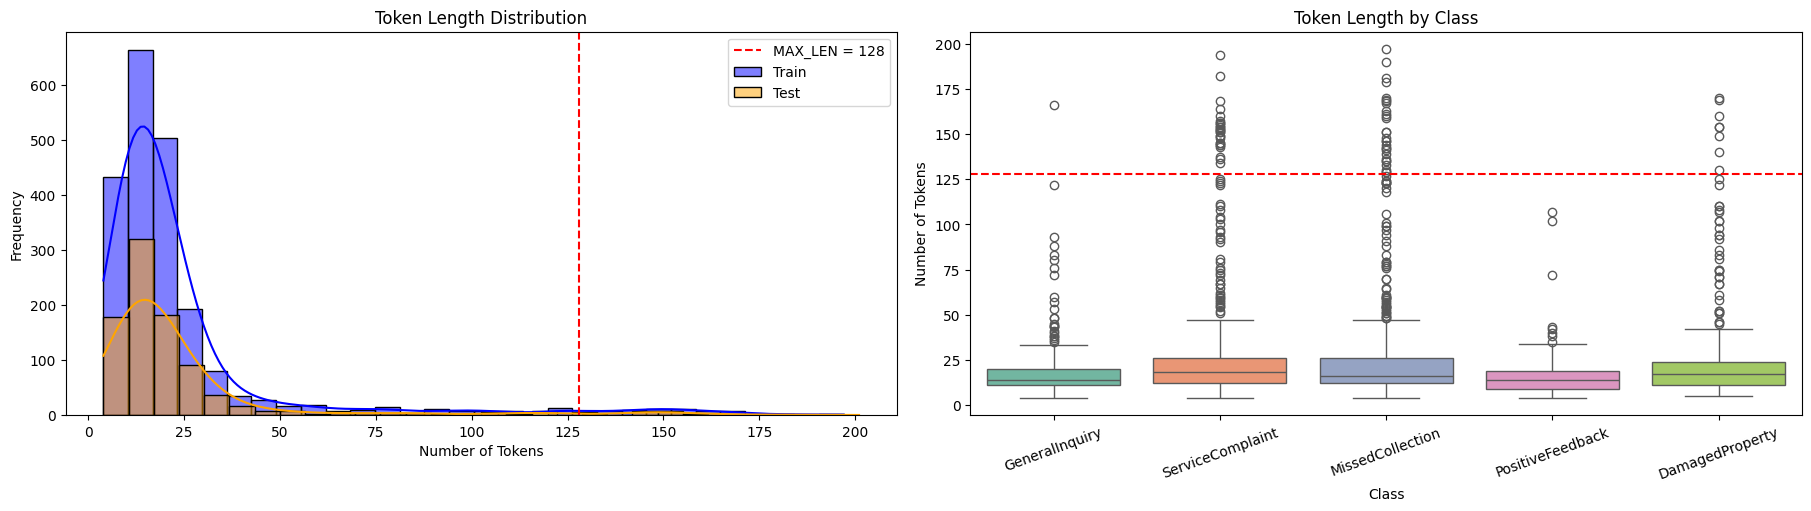

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(18, 5), constrained_layout=True)

# Left - Token Length Distribution
sns.histplot(train_df['token_length'], bins=30, color='blue', label='Train', kde=True, ax=axs[0])
sns.histplot(test_df['token_length'], bins=30, color='orange', label='Test', kde=True, ax=axs[0])
axs[0].axvline(MAX_LEN, color='red', linestyle='--', label=f'MAX_LEN = {MAX_LEN}')
axs[0].set_title('Token Length Distribution')
axs[0].set_xlabel('Number of Tokens')
axs[0].set_ylabel('Frequency')
axs[0].legend()

# Right - Token Length by Class
sns.boxplot(data=train_df, x='label', y='token_length', hue='label', palette='Set2', legend=False, ax=axs[1])
axs[1].axhline(MAX_LEN, color='red', linestyle='--')
axs[1].set_title('Token Length by Class')
axs[1].set_xlabel('Class')
axs[1].set_ylabel('Number of Tokens')
axs[1].tick_params(axis='x', rotation=20)

plt.show()

#### Text Length Findings

Token lengths are quite consistent between the splits (train mean **24.69**, test **24.58**; median **16** in both), outlining that the split is representative.

`MAX_LEN = 128` is still a good choice, as about **3%** of messages exceed it (**3.07%** train, **2.99%** test). However, the **Service Complaint** and **Missed Collection** classes show longer upper tails, so monitor per-class recall/F1 and the confusion matrix. If these classes underperform might be a good idea to trial a higher limmit like **160** or even **192**.

### Vocabulary Analysis

The objective in this section is to ... and 

- Lexical Seperability
- Tokenizer Fragmentation/Noise
- Language Check 

#### Class Lexical Seperability

The objective of this section is to determine what words/phrases are associated with each class to understand where possible classification confusion is likely to occur.

#### Noise Profile

The objective of this section is to see how much linguistic noise is present in the training data like **typos** or **shortened text speak** and whether that noise is likely to affect downstream model performance.

- Quantify shorthand usage and possible typos across the dataset.    
- Distinguish genuine noise from domain-specific terms to avoid over-cleaning useful signal.  
- Inform model choice and preprocessing decisions.

In [12]:
# Didn't get to completing this as not too necessary for my objective
# However just a look at the data will tell you that
# Shorthand and spelling mistakes are common

##### Noise Profile Findings

Manual review of messages clearly shows frequent shorthand (e.g., *pls, asap, didnt*) and spelling variation/mistakes across classes.

Because of this, a **transformer-based model** is the better choice over traditional approaches like **logistic regression**.  
- Logistic regression with bag-of-words/TF-IDF needs exact token matching, so misspellings and shorthand will degrade performance.  
- Transformers like BERT use **subword tokenisation** and **contextual embeddings**, making them a better choise with noisy data.

#### Language Check

The objective of this section is to do a brief check to confirm if the dataset only English. I will use this to validate model choice: if English dominates, fine-tuning an English model like BERT/RoBERTa is appropriate but if multilingual messages appear, I will use a multilingual model like XLM-RoBERTa.

In [13]:
from langdetect import detect, DetectorFactory, LangDetectException

DetectorFactory.seed = 0

def predicted_non_english(text, min_words=8):
    text = str(text).strip()
    if len(text.split()) < min_words:
        return False
    try:
        return detect(text) != 'en'
    except LangDetectException:
        return False

suspected_non_english = train_df[train_df['message'].apply(predicted_non_english)]
suspected_non_english_test = test_df[test_df['message'].apply(predicted_non_english)]

print(f"Predicted non-English rows (Train): {len(suspected_non_english)}")
with pd.option_context('display.max_colwidth', None):
    display(suspected_non_english[['label', 'message']])

print(f"\nPredicted non-English rows (Test): {len(suspected_non_english_test)}")
with pd.option_context('display.max_colwidth', None):
    display(suspected_non_english_test[['label', 'message']])

Predicted non-English rows (Train): 27


,label,message
107,DamagedProperty,"La semana pasada su camión chocó contra mi cerca de madera y ahora está partida. Necesito que la reparen pronto porque mis perros pueden escapar. Vivo en 9 Willow Close, Taunton. Tengo fotos y los vecinos vieron el impacto. Por favor indíquenme el procedimiento para reclamar los daños y el plazo estimado de reparación."
164,MissedCollection,missed AGAIN 😡 green bin still outside. do i just leave it forever or?
278,MissedCollection,Non ho ricevuto il ritiro oggi. Il mio cestino è ancora pieno. (I put it out last night but no one came?)
283,GeneralInquiry,"Ciao, volevo sapere se accettate plastica dura (tipo contenitori del detersivo)? Grazie!"
348,ServiceComplaint,Le service est lent et pas fiable ces jours-ci
358,MissedCollection,"Mi cubo no fue recogido hoy, siempre pasa lo mismo"
599,ServiceComplaint,"Buenos días, quiero presentar una queja sobre el servicio de reciclaje esta semana. Viajé por trabajo y dejé el contenedor listo, pero nadie vino. Gracias."
610,GeneralInquiry,hi how do i get a new green bin? mine got stolen last night :(
625,MissedCollection,"Hola, mi contenedor no fue recogido ayer, ¿pueden ayudarme? (Spanish: MissedCollection)"
771,MissedCollection,"nothing picked up, kids nappies piling up, not happy"



Predicted non-English rows (Test): 15


,label,message
146,MissedCollection,"green bin left untouched on pavement, rest of street same."
174,MissedCollection,BIN MISSING. COLLECTION NOT DONE. WHAT IS GOING ON??
239,DamagedProperty,"Team left bins rolling into my garden, broke pots"
369,GeneralInquiry,"bonjour, est-ce que le carton va dans le bac vert?"
372,MissedCollection,"bonjour, ma poubelle de recyclage n’a pas été vidée ce matin comme prévu. Pouvez-vous me dire si le service a été modifié? Merci."
378,GeneralInquiry,Do you accept drinks cartons and juice containers?
395,GeneralInquiry,Can I get a replacement bin? Mines disappeared
407,ServiceComplaint,"Hallo, ich bin ziemlich enttäuscht, dass Ihr Kundenservice meine letzte Nachricht einfach mit einer Standardantwort zurückgeschickt hat. Ich hatte spezifische Fragen zu den neuen Recyclingkategorien, aber bekam nur den FAQ-Link. Das wirkt unpersönlich und hilft nicht. I’m fluent in English too, so language isn’t the issue – I just want a tailored reply. Bitte gehen Sie auf individuelle Anfragen ein, sonst fühlt man sich ignoriert und wendet sich an andere Stellen."
423,ServiceComplaint,j’ai essayé de contacter le support mais aucune réponse depuis une semaine
435,MissedCollection,"Hola GreenBin! Mi nombre es Carla y vivo en 7 Brook Street, Taunton. Ayer dejaron mi contenedor verde sin vaciar mientras que los de mis vecinos sí fueron atendidos. No había objetos prohibidos dentro. Estaría muy agradecida si pudieran pasar de nuevo o indicar instrucciones. PS I checked the holiday schedule and it still says Tuesday is pickup for our postcode, so maybe fue un error. Tenemos un bebé de tres meses y el espacio en casa es limitado para guardar desechos. Gracias por su atención."


##### Language Check Findings

Pretty sweet and simple, there is obviously presence of multilingual content in both **train** and **test** however it only makes up for around `~2%` of each so using an english pretrained transformer is the way to go.  

### Text Characteristics

This section looks at things in customer messages like **emoji use**, **punctuation**, and **capitalisation**.

- Check whether these features are more common in certain classes.
- See if they help distinguish tone, especially in **Service Complaint**, **Missed Collection**, and **Positive Feedback**.  
- Decide whether these cues should be kept during preprocessing.

ultimately this section will just help me reinforce the fact that a transformer is a good choice based on the above explored things having a presence in the data set.


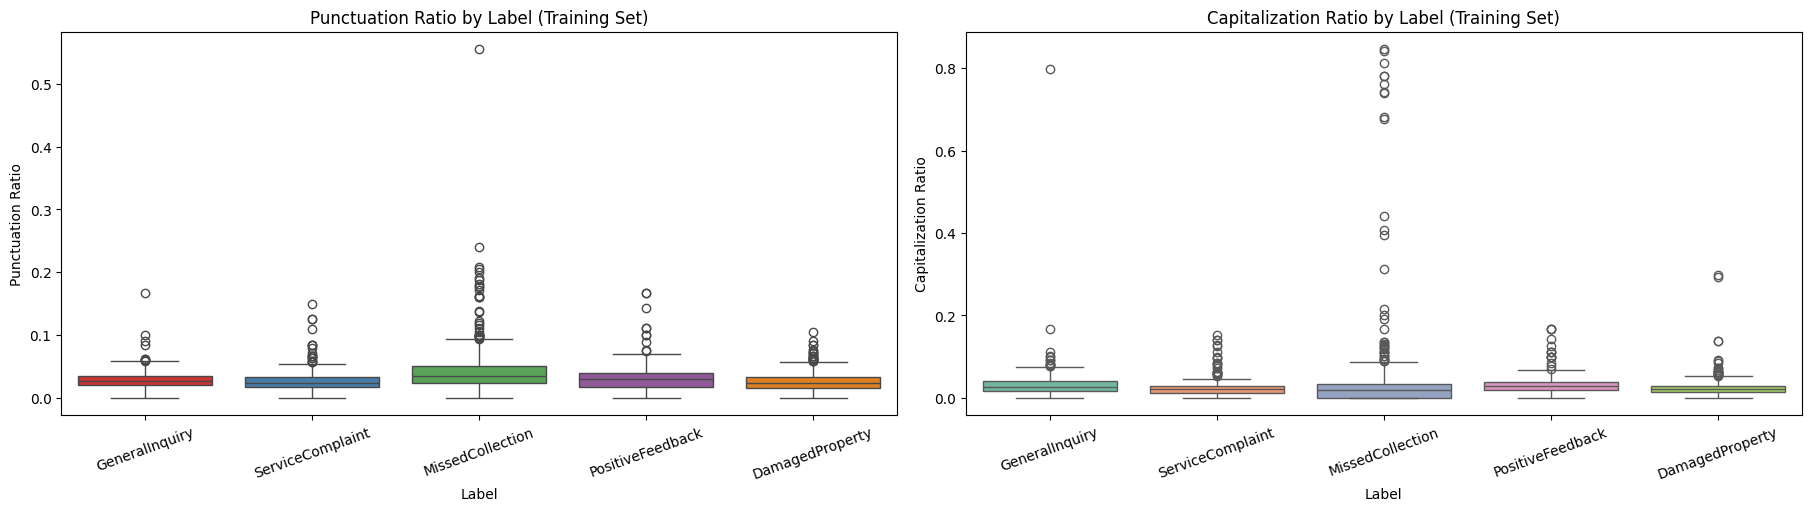

In [14]:
# Punctuation and Capitalisation
def punctuation_ratio(text):
    if len(text) == 0:
        return 0
    punct_count = sum(1 for char in text if char in string.punctuation)
    return punct_count / len(text)

def capitalization_ratio(text):
    if len(text) == 0:
        return 0
    capital_count = sum(1 for char in text if char.isupper())
    return capital_count / len(text)

train_df['punctuation_ratio'] = train_df['message'].apply(punctuation_ratio)
train_df['capitalization_ratio'] = train_df['message'].apply(capitalization_ratio)

fig, axes = plt.subplots(1, 2, figsize=(18, 5), constrained_layout=True)

sns.boxplot(
    x='label', y='punctuation_ratio', data=train_df,
    hue='label', palette='Set1', legend=False, ax=axes[0]
)
axes[0].set_title('Punctuation Ratio by Label (Training Set)')
axes[0].set_xlabel('Label')
axes[0].set_ylabel('Punctuation Ratio')
axes[0].tick_params(axis='x', rotation=20)

sns.boxplot(
    x='label', y='capitalization_ratio', data=train_df,
    hue='label', palette='Set2', legend=False, ax=axes[1]
)
axes[1].set_title('Capitalization Ratio by Label (Training Set)')
axes[1].set_xlabel('Label')
axes[1].set_ylabel('Capitalization Ratio')
axes[1].tick_params(axis='x', rotation=20)

plt.show()

In [15]:
## Emojis
import emoji
from IPython.display import display

train_df['emoji_list'] = train_df['message'].apply(
    lambda x: [match['emoji'] for match in emoji.emoji_list(x)]
)

emoji_tables = {}

for class_name, class_df in train_df.groupby('label', sort=False):
    class_emoji_counts = (
        class_df['emoji_list']
        .explode()
        .dropna()
        .value_counts()
        .head(4)
        .rename_axis('emoji')
        .reset_index(name='count')
    )

    if class_emoji_counts.empty:
        class_emoji_counts = pd.DataFrame({
            'emoji': ['None Found'],
            'count': ['N/a']
        })
    else:
        class_emoji_counts['count'] = class_emoji_counts['count'].replace(0, pd.NA)

    emoji_tables[class_name] = class_emoji_counts.reset_index(drop=True)

side_by_side_emojis = pd.concat(emoji_tables, axis=1)

for class_name in emoji_tables:
    count_col = (class_name, 'count')
    side_by_side_emojis[count_col] = side_by_side_emojis[count_col].fillna('N/a')

print('\nTop 4 Emojis by Class:')
display(side_by_side_emojis.style.hide(axis='index'))


Top 4 Emojis by Class:


#### Text Characteristics Findings

Emojis and expressive punctuation (for example repeated `!` and `?`) appear across classes. This further reinforces my decision when using a pre-trained transformer, which is better suited to capturing contextual signals in noisy text.


## Data Cleaning & Preprocessing <a id='data-cleaning-preprocessing'></a>

> After performing some preliminary checks which I have ommited to keep the notebook concise I have determined that there are no unicode issues so no and no control chars or null bytes found in the data.

In [16]:
# Normalise Whitespace Issues
message_series = train_df['message'].fillna('').astype(str)

multi_space_mask = message_series.str.contains(r' {2,}', regex=True, na=False)
tab_mask = message_series.str.contains(r'\t', regex=True, na=False)
newline_mask = message_series.str.contains(r'[\r\n]', regex=True, na=False)

whitespace_issue_mask = multi_space_mask | tab_mask | newline_mask

whitespace_check_summary = pd.DataFrame({
    'Check': [
        'Rows with multiple spaces',
        'Rows with tabs',
        'Rows with new lines',
        'Rows needing whitespace normalisation'
    ],
    'Count': [
        multi_space_mask.sum(),
        tab_mask.sum(),
        newline_mask.sum(),
        whitespace_issue_mask.sum()
    ]
})

display(HTML(whitespace_check_summary.to_html(index=False)))

if whitespace_issue_mask.any():
    whitespace_examples = train_df.loc[whitespace_issue_mask, ['label', 'message']].head(10).copy()
    whitespace_examples['message_visible'] = (
        whitespace_examples['message']
        .str.replace(' ', '·', regex=False)
        .str.replace('\t', r'\t', regex=False)
        .str.replace('\n', r'\n', regex=False)
        .str.replace('\r', r'\r', regex=False)
    )
    print('Whitespace normalisation fix applied.')
else:
    print('No whitespace normalisation issues found in the training set.')

Check,Count
Rows with multiple spaces,52
Rows with tabs,0
Rows with new lines,0
Rows needing whitespace normalisation,52


Whitespace normalisation fix applied.


In [17]:
# Encode Labels for model training
train_labels = train_df['label'].tolist()
classes = sorted(set(train_labels))

label2id = {label: i for i, label in enumerate(classes)}
id2label = {i: label for label, i in label2id.items()}

train_df['label_id'] = [label2id[lbl] for lbl in train_df['label']]
test_df['label_id'] = [label2id[lbl] for lbl in test_df['label']]

# Convert to torch tensors when needed
y_train = torch.tensor(train_df['label_id'].values, dtype=torch.long)
y_test = torch.tensor(test_df['label_id'].values, dtype=torch.long)

encodings = pd.DataFrame(
    list(label2id.items()),
    columns=['Name', 'Encoding']
)

display(HTML(encodings.to_html(index=False)))

Name,Encoding
DamagedProperty,0
GeneralInquiry,1
MissedCollection,2
PositiveFeedback,3
ServiceComplaint,4


## Modelling / Training <a id='modelling-training'></a>

This section focuses on building and fine-tuning a **supervised text classification model** to assign each customer message to one of the five target classes stated in the introduction of this notebook.

The modelling objective is to use a **pre-trained transformer (RoBERTa)** as the language backbone, with an attached **classification head** that maps contextual text embeddings to the task labels.

### Modelling Objectives
- Fine-tune the pre-trained model on the task-specific training data.  
- Learn class-discriminative features from customer message context.    
- Handle class imbalance through weighted training and evaluate with suitable classification metrics.

> **Model choice rationale (from EDA):** This approach was selected because the data contains noisy and informal language (e.g., shorthand, spelling variation, expressive punctuation/emojis), class imbalance, and is predominantly English, making an English pre-trained transformer the most appropriate baseline.

### Class Weights (Handle Imbalance)

EDA highlighted moderate class skew in the training data (for example, **Missed Collection** is notably more frequent than **Positive Feedback**).  
To handle this, class weights are calculated from the training label counts and then used in the loss function during training.

The weighting uses inverse class frequency so that under-represented classes receive a larger penalty when misclassified, this encourages more balanced learning across categories, rather than over-prioritising majority classes, and supports fairer macro-level performance (especially macro F1 and recall).

In [18]:
# Compute Class Weights
NUM_CLASSES = len(classes)

label_ids = torch.tensor(train_df['label_id'].values, dtype=torch.long)
class_counts = torch.bincount(label_ids, minlength=NUM_CLASSES).float()

class_weights = class_counts.sum() / (NUM_CLASSES * class_counts)
class_weights_tensor = class_weights.to(DEVICE)

class_weight_table = pd.DataFrame({
    'Class': classes,
    'Weight': class_weights.cpu().tolist()
})

display(HTML(class_weight_table.to_html(index=False, float_format=lambda x: f"{x:.3f}")))

Class,Weight
DamagedProperty,1.073
GeneralInquiry,1.149
MissedCollection,0.733
PositiveFeedback,1.482
ServiceComplaint,0.863


### Dataset and Data Loaders

This section is only responsible for creating the **PyTorch Dataset** objects and their corresponding **DataLoaders**.

- Build `MessageDataset` from `train_df` and `test_df`
- Tokenise message text and pair inputs with `label_id`
- Create batched loaders (`train_dl`, `test_dl`) for training/evaluation loops

In [19]:
# Datasets and DataLoaders
class MessageDataset(Dataset):
    """Tokenises messages and pairs them with integer labels."""
    def __init__(self, df, tokenizer):
        self.encodings = tokenizer(
            df['message'].tolist(),
            truncation=True,
            padding='max_length',
            max_length=MAX_LEN,
            return_tensors='pt'
        )
        self.labels = torch.tensor(df['label_id'].tolist(), dtype=torch.long)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {k: v[idx] for k, v in self.encodings.items()}, self.labels[idx]

tokenizer = RobertaTokenizer.from_pretrained(MODEL_NAME)
train_ds = MessageDataset(train_df, tokenizer)
test_ds = MessageDataset(test_df,  tokenizer)
train_dl = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
test_dl = DataLoader(test_ds,  batch_size=BATCH_SIZE)

print(f'Train Batches : {len(train_dl)}')
print(f'Test Batches : {len(test_dl)}')

Train Batches : 67
Test Batches : 29


### Model Archiecture

This model uses a **RoBERTa-base encoder + MLP classification head** for 5-class email categorisation.

#### Architecture summary
- **Backbone:** `roberta-base` (pre-trained language encoder).
- **Text representation:** pooled sequence embedding (`pooler_output`, size **768**).
- **Classification head:**  
    - `Dropout(0.3)`  
    - `Linear(768 → 384)`  
    - `GELU`  
    - `Dropout(0.3)`  
    - `Linear(384 → 5)`  
- **Training loss:** weighted `CrossEntropyLoss` (to handle class imbalance).
- **Output for inference:** class probabilities via softmax.

#### Why this design was chosen
- **RoBERTa backbone:** best fit for noisy customer text (spelling variation, shorthand, punctuation/emojis) because contextual embeddings are more robust than bag-of-words methods.
- **Linear layers:** efficient way to transform RoBERTa features into task-specific decision boundaries without over-complicating the head.
- **GELU activation:** standard transformer-friendly non-linearity; smoother than ReLU and generally stable for NLP fine-tuning.
- **Dropout (0.3):** reduces overfitting risk on a relatively small training set.
- **Weighted cross-entropy:** gives minority classes a stronger penalty signal, supporting better macro-level performance (especially macro F1/recall).

In [20]:
# Model Definition
class RobertaMessageClassifier(nn.Module):
    """
    RoBERTa encoder with a two-layer MLP classification head.
    Softmax is applied only at inference; training uses raw logits with
    weighted CrossEntropyLoss.
    """
    def __init__(self, num_classes=NUM_CLASSES, dropout=DROPOUT):
        super().__init__()
        self.roberta = RobertaModel.from_pretrained(MODEL_NAME)
        hidden = self.roberta.config.hidden_size  # 768

        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden, hidden // 2),       # 768 → 384
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden // 2, num_classes)   # 384 → num_classes
        )
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, input_ids, attention_mask, labels=None):
        pooled = self.roberta(
            input_ids=input_ids,
            attention_mask=attention_mask
        ).pooler_output                            # [B, 768]

        logits = self.classifier(pooled)           # [B, num_classes]
        loss   = None
        if labels is not None:
            loss = nn.CrossEntropyLoss(weight=class_weights_tensor)(logits, labels)

        return loss, self.softmax(logits)


model = RobertaMessageClassifier().to(DEVICE)
print(f'Trainable parameters: {sum(p.numel() for p in model.parameters()):,}')

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 5838.97it/s]
RobertaModel LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
pooler.dense.bias               | MISSING    | 
pooler.dense.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable parameters: 124,942,853


### Optimiser and Sheduler

This section sets up the training optimisation step by initialising **AdamW** for the model parameters (using the configured learning rate and weight decay). It also creates a **LambdaLR** scheduler via an `lr_lambda` function, applying a short warm-up phase before linearly decaying the learning rate over the remaining training steps.

In [21]:
optimizer = AdamW(model.parameters(), lr=LR, weight_decay=0.01)

total_steps = len(train_dl) * EPOCHS
warmup_steps = total_steps // 10

def lr_lambda(current_step):
    if current_step < warmup_steps:
        return float(current_step + 1) / float(max(1, warmup_steps))
    return max(
        0.0,
        float(total_steps - current_step) / float(max(1, total_steps - warmup_steps))
    )

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

print(f'Total steps: {total_steps} | Warmup: {warmup_steps}')

Total steps: 670 | Warmup: 67


### Model Training

This section fine-tunes the RoBERTa classifier on the training split using mini-batches from the train dataloader.

For each epoch, the model:
- Runs a forward pass and computes weighted cross-entropy loss,
- Backpropagates gradients,
- Applies gradient clipping for stability,
- Updates parameters with `AdamW`,
- Steps the learning-rate scheduler (warm-up + linear decay).

After each epoch, performance is evaluated on the test dataloader, tracking **training loss**, **validation loss**, and **validation accuracy**.  
The best-performing checkpoint (by validation accuracy) is saved for final evaluation, and per-epoch results are stored in `history`.

In [22]:
# Training and Evaluation Helpers
def train_epoch(model, loader, epoch):
    model.train()
    total_loss = 0.0

    train_bar = tqdm.tqdm(
        loader,
        desc=f"Epoch {epoch}/{EPOCHS} [Train]",
        unit="batch",
        leave=False
    )

    for step, (batch, labels) in enumerate(train_bar, start=1):
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        labels = labels.to(DEVICE)

        optimizer.zero_grad()
        loss, _ = model(**batch, labels=labels)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()
        train_bar.set_postfix(
            loss=f"{(total_loss / step):.4f}",
            lr=f"{optimizer.param_groups[0]['lr']:.2e}"
        )

    return total_loss / len(loader)


def evaluate_epoch(model, loader, epoch=None):
    model.eval()
    all_preds, all_labels = [], []
    total_loss = 0.0

    val_desc = f"Epoch {epoch}/{EPOCHS} [Val]" if epoch is not None else "Evaluation"
    val_bar = tqdm.tqdm(
        loader,
        desc=val_desc,
        unit="batch",
        leave=False
    )

    with torch.no_grad():
        for step, (batch, labels) in enumerate(val_bar, start=1):
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            labels = labels.to(DEVICE)

            loss, probs = model(**batch, labels=labels)
            preds = probs.argmax(dim=-1)

            all_preds.extend(preds.cpu().tolist())
            all_labels.extend(labels.cpu().tolist())
            total_loss += loss.item()

            val_bar.set_postfix(loss=f"{(total_loss / step):.4f}")

    acc = sum(p == l for p, l in zip(all_preds, all_labels)) / len(all_labels)
    return total_loss / len(loader), acc, all_preds, all_labels


# Training Loop with Checkpointing
best_acc = 0.0
history = []
checkpoint_path = Path("best_roberta.pt")

for epoch in range(1, EPOCHS + 1):
    tr_loss = train_epoch(model, train_dl, epoch)
    val_loss, val_acc, _, _ = evaluate_epoch(model, test_dl, epoch)

    history.append({
        "epoch": epoch,
        "tr_loss": tr_loss,
        "val_loss": val_loss,
        "val_acc": val_acc
    })

    print(
        f"Epoch {epoch}/{EPOCHS} | "
        f"train_loss={tr_loss:.4f} | val_loss={val_loss:.4f} | val_acc={val_acc:.4f}"
    )

    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), checkpoint_path)
        print(f"Checkpoint Saved: Validation Accuracy={best_acc:.4f}")

print(f"\nBest Validation Accuracy: {best_acc:.4f}")
print(f"Checkpoint exists: {checkpoint_path.exists()} ({checkpoint_path.resolve()})")

Epoch 1/10 | train_loss=1.5550 | val_loss=1.0723 | val_acc=0.8960
Checkpoint Saved: Validation Accuracy=0.8960


Epoch 2/10 | train_loss=0.5638 | val_loss=0.2297 | val_acc=0.9657
Checkpoint Saved: Validation Accuracy=0.9657


Epoch 3/10 | train_loss=0.1763 | val_loss=0.1279 | val_acc=0.9735
Checkpoint Saved: Validation Accuracy=0.9735


Epoch 4/10 | train_loss=0.0724 | val_loss=0.1430 | val_acc=0.9679


Epoch 5/10 | train_loss=0.0428 | val_loss=0.1345 | val_acc=0.9668


Epoch 6/10 | train_loss=0.0344 | val_loss=0.1161 | val_acc=0.9812
Checkpoint Saved: Validation Accuracy=0.9812


Epoch 7/10 | train_loss=0.0203 | val_loss=0.1363 | val_acc=0.9701


Epoch 8/10 | train_loss=0.0137 | val_loss=0.1215 | val_acc=0.9779


Epoch 9/10 | train_loss=0.0107 | val_loss=0.1280 | val_acc=0.9790


Epoch 10/10 | train_loss=0.0106 | val_loss=0.1229 | val_acc=0.9779

Best Validation Accuracy: 0.9812
Checkpoint exists: True (E:\feedback-classification\best_roberta.pt)


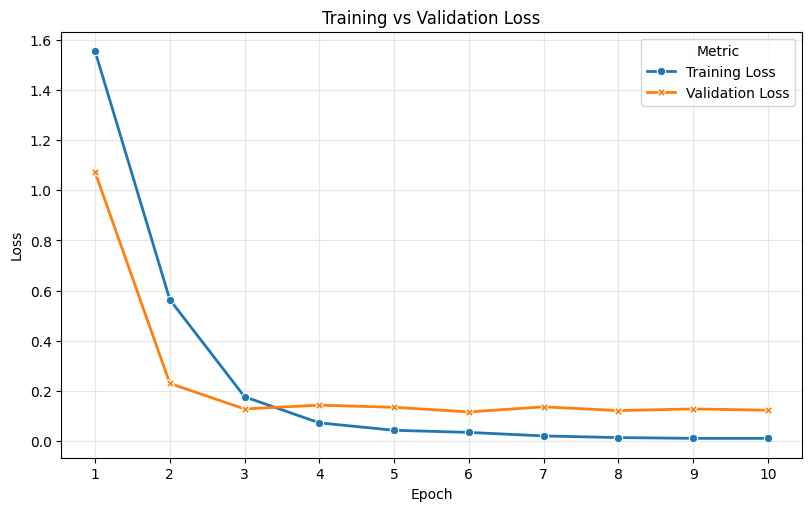

In [23]:
history_df = pd.DataFrame(history).sort_values('epoch').reset_index(drop=True)

plot_df = history_df.melt(id_vars='epoch', value_vars=['tr_loss', 'val_loss'], var_name='Metric', value_name='Loss').replace({
    'Metric': {
        'tr_loss': 'Training Loss',
        'val_loss': 'Validation Loss'
    }
})

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
sns.lineplot(data=plot_df, x='epoch', y='Loss', hue='Metric', style='Metric', markers=True, dashes=False, linewidth=2, ax=ax)

ax.set_title('Training vs Validation Loss')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_xticks(history_df['epoch'])
ax.grid(alpha=0.3)

plt.show()

## Evaluation <a id='evaluation'></a>

This section evaluates the fine-tuned RoBERTa classifier against the provided test set using metrics suited to a multi-class imbalanced classification task.

- **Accuracy** – Overall proportion of correctly classified messages, used as a high-level indicator.
- **Macro F1, Precision & Recall** – Weighted equally across all categories, ensuring minority classes are not masked by majority performance.
- **Per-Class Precision, Recall & F1** – Breakdown by target category to identify which classes the model struggles with most.
- **Confusion Matrix** – Visual representation of misclassification patterns.

In [24]:
# Evaluation Metrics Report
checkpoint_path = Path('best_roberta.pt')
if not checkpoint_path.exists():
    raise FileNotFoundError(f'Checkpoint not found: {checkpoint_path.resolve()}')

# Recreate model only if model was overwritten in the notebook state
if 'model' not in globals() or not isinstance(model, nn.Module):
    model = RobertaMessageClassifier().to(DEVICE)

state_dict = torch.load(checkpoint_path, map_location=DEVICE)
model.load_state_dict(state_dict)
model.to(DEVICE)

_, _, rob_preds, rob_labels = evaluate_epoch(model, test_dl)

y_true = torch.tensor(rob_labels, dtype=torch.long)
y_pred = torch.tensor(rob_preds, dtype=torch.long)

num_classes = len(classes)

# Confusion matrix
cm = torch.zeros((num_classes, num_classes), dtype=torch.long)
for t, p in zip(y_true, y_pred):
    cm[t, p] += 1

tp = cm.diag().float()
fp = cm.sum(dim=0).float() - tp
fn = cm.sum(dim=1).float() - tp
support = cm.sum(dim=1).float()

precision = tp / (tp + fp).clamp_min(1.0)
recall = tp / (tp + fn).clamp_min(1.0)
f1 = 2 * precision * recall / (precision + recall).clamp_min(1e-12)

accuracy = (y_true == y_pred).float().mean().item()

summary_df = pd.DataFrame([{
    'Accuracy': accuracy,
    'Macro Precision': precision.mean().item(),
    'Macro Recall': recall.mean().item(),
    'Macro F1': f1.mean().item()
}]).round(3)

report_df = pd.DataFrame({
    'Class': classes,
    'Precision': precision.numpy(),
    'Recall': recall.numpy(),
    'F1': f1.numpy(),
    'Support': support.numpy().astype(int)
}).round(3)

print('─' * 50)
print('RoBERTa Evaluation Summary:')
display(HTML(summary_df.to_html(index=False)))
display(HTML(report_df.to_html(index=False)))

──────────────────────────────────────────────────
RoBERTa Evaluation Summary:


Accuracy,Macro Precision,Macro Recall,Macro F1
0.981,0.982,0.982,0.982


Class,Precision,Recall,F1,Support
DamagedProperty,0.970,0.970,0.970,168
GeneralInquiry,0.987,1.000,0.994,157
MissedCollection,0.980,0.996,0.988,247
PositiveFeedback,0.992,0.992,0.992,122
ServiceComplaint,0.980,0.952,0.966,210


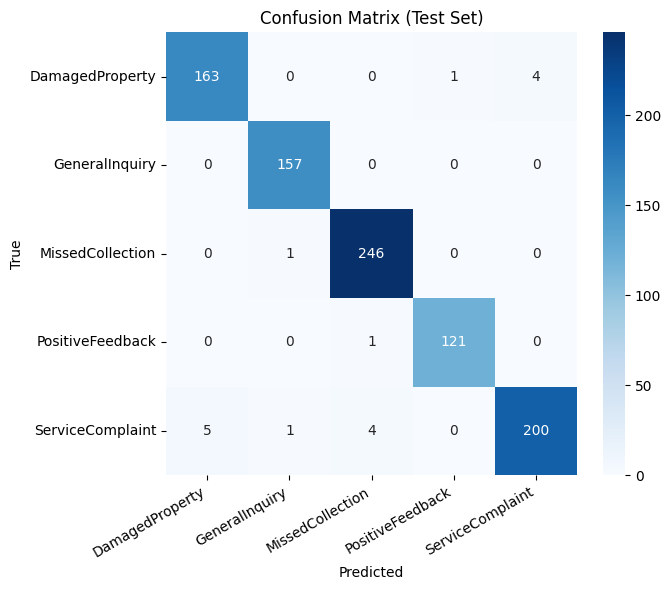

In [25]:
plt.figure(figsize=(7, 6))
ax = sns.heatmap(
    cm.numpy(),
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=classes,
    yticklabels=classes
)

ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')
plt.title('Confusion Matrix (Test Set)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.tight_layout()
plt.show()

### Confusion Matrix Findings

The confusion matrix highlights a slight overlap between the complaint-related classes:

- **Damaged Property** was misclassified as **Service Complaint**.  
- **Missed Collection** also showed confusion with **Service Complaint**.  
- The largest spread of misclassification came from **Service Complaint**, which was predicted across multiple non-positive classes.  
- **Positive Feedback** stood out as the cleanest class, with little to no confusion and effectively perfect classification in this run.

## Conclusion <a id='conclusion'></a>

This project successfully built an end-to-end NLP classification pipeline to assign customer emails to five service categories (**Damaged Property, General Inquiry, Missed Collection, Positive Feedback, Service Complaint**). The workflow covered ingestion, EDA, preprocessing, weighted transformer training, and evaluation, with findings showing moderate class imbalance, strong data quality (no missing/duplicate core fields), mostly short texts (supporting `MAX_LEN=128`), noisy real-world language, and predominantly English content.

Using these insights, a **RoBERTa-based classifier** with class-weighted loss was fine-tuned and delivered strong held-out performance (**validation accuracy: 97.46%**, **validation loss: 0.121**). Overall, the objective was met: the notebook demonstrates a robust baseline that can be extended with stronger checkpointing, richer error analysis, and targeted improvements for minority/overlapping classes.

### Areas for Improvement:

- Look at comparison of other pretrained transformers like `distilroberta-base` or `deberta-v3-base`.
- Another thing that I could implement is adding dynamic padding.
- Use CUDA mixed precision to see if improves training time without degrading accuracy. 

---

## Appendix
- **Author:** Morrison Page
- **Environment:** `Kernal - Python 3.12.3`
